# Kaizen — EDA и проверка качества данных

Разведочный анализ и машинное обучение по реестру КП:

1. Загрузка и очистка данных;
2. EDA: распределения, динамика, корпуса, корреляции, выбросы, авторы;
3. Статистические гипотезы H1–H6;
4. ML: классификация одобрения, важность признаков, ROC, CV, тюнинг;
5. Интерпретация, прогноз и сохранение результатов.

Датасет: `Завод/КП реестр(4).csv`.

# Установка зависимостей

pip install -q pandas numpy matplotlib seaborn scipy scikit-learn catboost shap joblib

In [13]:
import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

from catboost import CatBoostClassifier

import shap
import joblib

from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [14]:
# ============================================================
# ЗАГРУЗКА ДАННЫХ
# ============================================================

DATA_PATH = "/home/andor/Рабочий стол/Завод/КП реестр(4).csv"
os.makedirs("figures", exist_ok=True)

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    encoding="utf-8-sig"
)

print("Размер исходного датазета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)

Размер исходного датазета: (13535, 23)

Названия столбцов:
['Корпус', '№ РГ/МГ', '№ КП', 'Подано', 'Автор', 'Таб номер авторов', 'Месяц ФАКТ снятия', 'Описание', 'Условно-годовой ЭЭ', 'Фактический ЭЭ', 'Сумма', 'Компенсации затрат', 'Вид экономии', 'Отклонено', 'Реализовано', 'Отдано в работу', 'Где в работе', 'Где в работе, корпус', 'Задача', 'Срок выполнения', 'Комментарии', 'Было ли КП в реестре на выплаты', 'Снималось ли КП по форме 12Д']

Первые 5 строк:


,Корпус,№ РГ/МГ,№ КП,Подано,Автор,Таб номер авторов,Месяц ФАКТ снятия,Описание,Условно-годовой ЭЭ,Фактический ЭЭ,...,Отклонено,Реализовано,Отдано в работу,Где в работе,"Где в работе, корпус",Задача,Срок выполнения,Комментарии,Было ли КП в реестре на выплаты,Снималось ли КП по форме 12Д
0,УГТ,107.10,ИС107-09-404,04.03.2026,Мирошниченко Наталия Николаевна (100%),107071,4.0,В ТП 142.03.02.040 С1 ТП; 142.03.02.060 С1 ТП;...,"6088,40",NaN,...,NaN,23.03.2026,NaN,NaN,NaN,NaN,NaN,*04.2026,Да,Нет
1,ТЛК,89.01,ИС089-01-039,09.02.2026,"Ковалева Марина Евгеньевна (35%),Губанов Влади...","111001,37093,109061",NaN,В настоящее время готовая продукция комбайны К...,"91350,00",NaN,...,NaN,NaN,10.02.2026,Кривенко Вячеслав Анатольевич,NaN,NaN,NaN,1. РЖД (Перевозчик) регламентирует типы ЗПУ пр...,Нет,Нет
2,УГТ,178.07,ИС178-07-250,25.07.2024,"Захарова Лилия Александровна (60%),Шеверев Евг...","25610,51680",10.0,Высокая загрузка окрасочной линии №3. 142.01.5...,"169827,30",NaN,...,NaN,05.09.2024,NaN,NaN,NaN,NaN,NaN,*10.2024,Да,Нет
3,МСК-1,30.06,ИС030-06-362,23.01.2026,"Кобзарев Василий Викторович (50%),Гольдинов Ма...","38645,23484",NaN,В связи с повышением плана выпускаемой продукц...,NaN,NaN,...,NaN,NaN,26.01.2026,NaN,NaN,реализ,NaN,-,Нет,Нет
4,МСК-1,19.02,ИС019-02-315,29.01.2026,Прокопенко Сергей Владимирович (100%),9228,NaN,Отсутствует настил на рабочем месте,NaN,NaN,...,NaN,12.02.2026,NaN,NaN,NaN,NaN,NaN,Настил изготовлен самостоятельно.,Нет,Нет



Типы данных:
Корпус                                 str
№ РГ/МГ                            float64
№ КП                                   str
Подано                                 str
Автор                                  str
Таб номер авторов                      str
Месяц ФАКТ снятия                  float64
Описание                               str
Условно-годовой ЭЭ                     str
Фактический ЭЭ                         str
Сумма                              float64
Компенсации затрат                 float64
Вид экономии                       float64
Отклонено                              str
Реализовано                            str
Отдано в работу                        str
Где в работе                           str
Где в работе, корпус                   str
Задача                                 str
Срок выполнения                        str
Комментарии                            str
Было ли КП в реестре на выплаты        str
Снималось ли КП по форме 12Д           s

### Выводы по загрузке данных

Была загуржена база из 13 535 кайдзен-предложений (23 поля). При первичном осмотре стало понятно, с чем можно работать, а какие данные в системе практически не ведутся.

Форматы нужно приводить в порядок, числа (например, плановый эффект) и даты записаны в таблицу как обычный текст, поэтому перед расчётами их потребуется очистить и перевести в правильный формат.

Финансовые и плановые поля не заполняются. Столбцы «Сумма», «Компенсации затрат» и «Вид экономии» не заполнены совсем. Фактический экономический эффект указан только у 1,5% заявок, а плановый срок выполнения — примерно у 6%.

Оценить реальную денежную окупаемость инициатив не получится, так как эти данные в реестр почти не вносятся. Зато в базе отлично зафиксирован сам путь заявки — когда подана, кем, в каком корпусе, принята в работу или отклонена.

In [3]:
# ============================================================
# ОЧИСТКА И FEATURE ENGINEERING
# ============================================================

required_columns = [
    "Подано", "Реализовано", "Отдано в работу", "Отклонено",
    "Срок выполнения", "Автор", "Условно-годовой ЭЭ",
    "Фактический ЭЭ", "№ КП", "Корпус", "Задача", "Вид экономии",
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"В CSV отсутствуют необходимые столбцы: {missing_columns}")


def parse_date(value):
    if pd.isna(value):
        return pd.NaT
    value = str(value).strip()
    if not value or value.lower() in ("nan", "nat", "none"):
        return pd.NaT
    match = re.fullmatch(r"(\d{1,2})\.(\d{1,2})\.(\d{4})", value)
    if match:
        try:
            return pd.Timestamp(
                year=int(match.group(3)),
                month=int(match.group(2)),
                day=int(match.group(1)),
            )
        except ValueError:
            return pd.NaT
    try:
        return pd.to_datetime(value, errors="coerce", dayfirst=True)
    except (ValueError, TypeError):
        return pd.NaT


date_columns = ["Подано", "Реализовано", "Отдано в работу",
                "Отклонено", "Срок выполнения"]
for col in date_columns:
    df[col + "_dt"] = df[col].apply(parse_date)


def to_num(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if not value or value.lower() in ("nan", "none"):
        return np.nan
    value = (
        value.replace("\u00a0", "").replace(" ", "")
        .replace("₽", "").replace(",", ".")
    )
    try:
        return float(value)
    except (ValueError, TypeError):
        return np.nan


def author_pct(value):
    if pd.isna(value):
        return np.nan
    parts = [
        p.strip() for p in str(value).replace(";", ",").split(",")
        if p.strip()
    ]
    if not parts:
        return np.nan
    match = re.match(r"^(.*?)\s*\((\d+(?:[.,]\d+)?)%?\)$", parts[0])
    if match:
        return float(match.group(2).replace(",", "."))
    return np.nan


df["author_pct"] = df["Автор"].apply(author_pct)
df["planned_economy"] = df["Условно-годовой ЭЭ"].apply(to_num)
df["actual_economy"] = df["Фактический ЭЭ"].apply(to_num)

df["is_rejected"] = df["Отклонено_dt"].notna()
df["is_implemented"] = df["Реализовано_dt"].notna()
df["is_in_progress"] = (
    df["Отдано в работу_dt"].notna()
    & df["Реализовано_dt"].isna()
    & ~df["is_rejected"]
)
df["is_approved"] = (
    df["is_implemented"] | df["is_in_progress"]
).astype(int)

df["task_status"] = df["Задача"].fillna("unknown").astype(str)
df["economy_type"] = df["Вид экономии"].fillna("unknown").astype(str)

decision_date = (
    df["Отклонено_dt"]
    .combine_first(df["Реализовано_dt"])
    .combine_first(df["Отдано в работу_dt"])
)
df["time_to_decision_days"] = (decision_date - df["Подано_dt"]).dt.days
df["implementation_time_days"] = (
    df["Реализовано_dt"] - df["Подано_dt"]
).dt.days
df["season"] = df["Подано_dt"].dt.month

df["КП_norm"] = df["№ КП"].astype(str).str.replace(r"\s+", "", regex=True)
rows_before = len(df)
df = (
    df.drop_duplicates(subset="КП_norm", keep="first")
    .drop(columns="КП_norm")
    .reset_index(drop=True)
)

print("\nУдалено дубликатов:", rows_before - len(df))
print("Размер очищенного датасета:", df.shape)
print("\nПропущенные значения:")
print(df.isna().sum())


Удалено дубликатов: 10
Размер очищенного датасета: (13525, 40)

Пропущенные значения:
Корпус                                 0
№ РГ/МГ                                0
№ КП                                   0
Подано                                 0
Автор                                  0
Таб номер авторов                      0
Месяц ФАКТ снятия                  12221
Описание                               7
Условно-годовой ЭЭ                  6752
Фактический ЭЭ                     13181
Сумма                              13525
Компенсации затрат                 13525
Вид экономии                       13525
Отклонено                          11074
Реализовано                         5777
Отдано в работу                    10203
Где в работе                       11508
Где в работе, корпус               12832
Задача                             11441
Срок выполнения                    12716
Комментарии                         8401
Было ли КП в реестре на выплаты        0
Снималось л

### Выводы по очистке и feature engineering

После очистки данных и удаления 10 случайных дублей в работе осталось 13 525 уникальных предложений. Основные наблюдения на этом этапе:

* Целевая переменная сильно разбалансирована, одобрено 11 075 КП (81,8%), не одобрено 2 456 (18,2%). Внутри одобренных: 7 753 реализовано, 3 322 в работе, 4 без движения.

* Медиана срока реализации - 3 дня, но среднее — 41 день (p90 ≈ 133 дня): распределение с длинным правым хвостом, типичное для «быстрых» и «зависших» КП.

* Полностью бесполезен как признак `economy_type` («Вид экономии» пуст → везде `unknown`), также выпадают `actual_economy` и `Срок выполнения` (≈95–97% пропусков).

* Из-за дисбаланса 82/18 accuracy не показателен, модель «всё одобрить» уже даёт 0,82. Ориентироваться нужно на ROC-AUC и recall по классу «не одобрено».

Итог, для прогноза доступны корпус, автор, заявленная экономия, сезон и статус задачи; целевой класс несбалансирован, а сроки реализации крайне неоднородны.

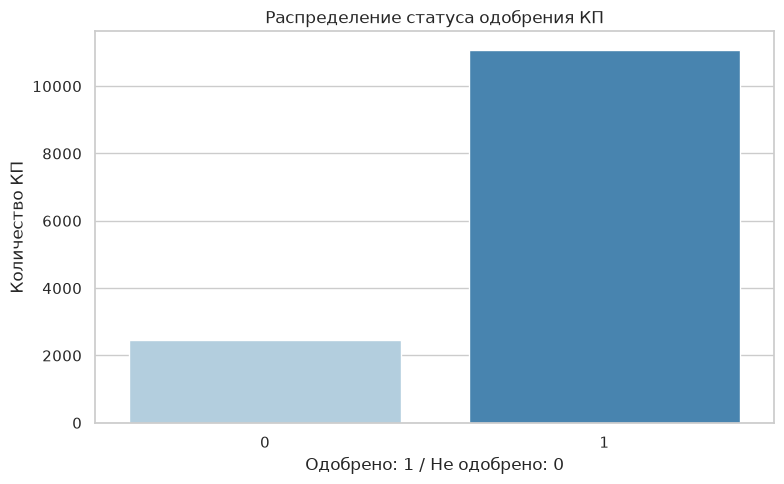

In [4]:
# ============================================================
# EDA
# ============================================================

# ---------- Распределение одобрения ----------
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="is_approved", hue="is_approved",
              palette="Blues", legend=False)
plt.title("Распределение статуса одобрения КП")
plt.xlabel("Одобрено: 1 / Не одобрено: 0")
plt.ylabel("Количество КП")
plt.tight_layout()
plt.savefig(f"figures/fig_01.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по распределению одобрения

82% КП одобряются (реализованы или взяты в работу), 18% отклоняются. То есть узкое место не в отказе, а в доведении до результата.

Дисбаланс классов означает, что «высокая точность» модели сама по себе ничего не доказывает так как базовый уровень 0,82 достигается без обучения.

Метрики моделей нужно будет сравнивать с порогом accuracy ≈ 0,82 и отдельно смотреть на качество распознавания отклонённых КП.

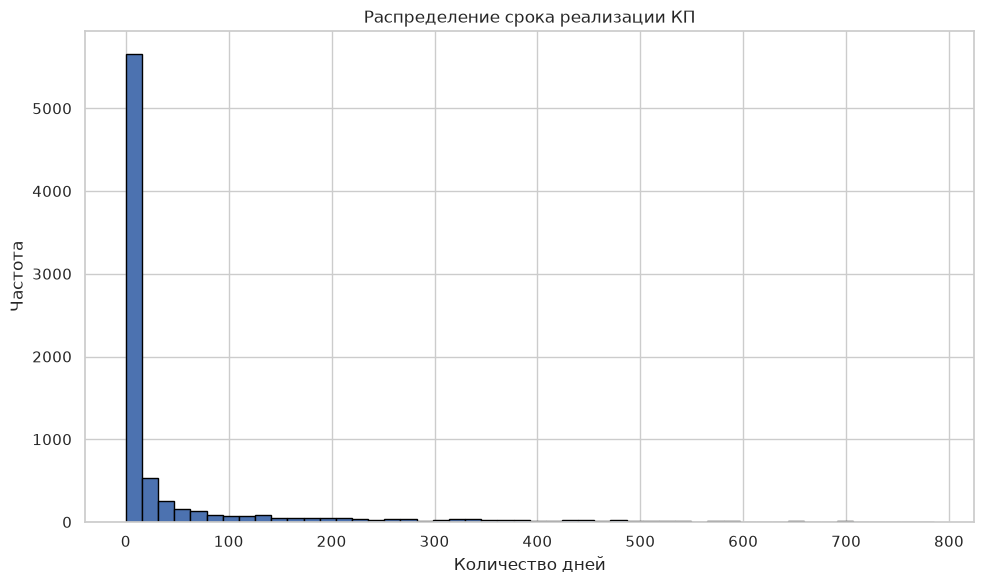

In [5]:
# ---------- Время реализации ----------
implementation_times = (
    df.loc[df["implementation_time_days"] >= 0,
           "implementation_time_days"].dropna()
)
plt.figure(figsize=(10, 6))
plt.hist(implementation_times, bins=50, edgecolor="black")
plt.title("Распределение срока реализации КП")
plt.xlabel("Количество дней")
plt.ylabel("Частота")
plt.tight_layout()
plt.savefig(f"figures/fig_02.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по срокам реализации

Большинство КП закрывается за считанные дни (медиана 3 дня), но предложения с долгой реализацией (до 133+ дней) у 10% самых медленных.

Среднее (41 день) в 14 раз больше медианы — типичный признак смеси двух процессов: формальные быстрые КП и реальные проекты с длинной реализацией.

Модель по средним значениям будет ошибаться, корректнее оценивать медиану/квантили, а метрику RMSE считать по логарифму срока.

Быстрые закрытия стоит проверить отдельно, часть из них, вероятно, административные (КП уже было выполнено на момент подачи), и они искажают оценку эффективности процесса.

Итог, «средний срок реализации» — плохая метрика для этого процесса, управлять нужно медианой и хвостом долгих КП.

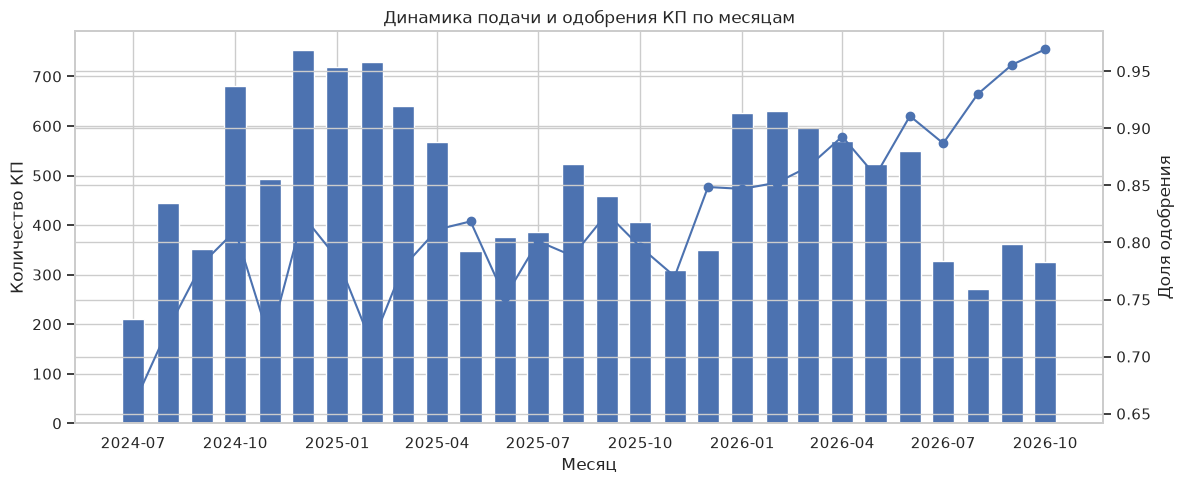

In [6]:
# ---------- Динамика по месяцам ----------
monthly = (
    df.dropna(subset=["Подано_dt"])
    .groupby(df["Подано_dt"].dt.to_period("M"))["is_approved"]
    .agg(["count", "sum"])
)
monthly["approval_rate"] = monthly["sum"] / monthly["count"]
monthly.index = monthly.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(monthly.index, monthly["count"], width=20, label="Количество КП")
ax1.set_ylabel("Количество КП")
ax1.set_xlabel("Месяц")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["approval_rate"],
         marker="o", label="Доля одобрения")
ax2.set_ylabel("Доля одобрения")
plt.title("Динамика подачи и одобрения КП по месяцам")
fig.tight_layout()
plt.savefig(f"figures/fig_03.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по динамике по месяцам

Объём подачи нестабилен: пики — декабрь 2024 (754 КП), октябрь 2024 (681), февраль 2025 (730), спад — июль 2024 (210) и лето 2025 (≈375–390). Похоже на сезонность и на «закрытие года».

Процент одобрения стабильно растёт. Если в июле 2024 года принималось 66% предложений, то к лету–осени 2026 года этот показатель вырос до 91–97%. Часть этого роста артефакт данных, у свежих КП просто не прошло достаточно времени, чтобы получить отказ (медиана времени до отказа — 35 дней).

Итог, вовлечённость сотрудников имеет чёткую сезонность, а процесс согласования стал лояльнее. Однако, финальную статистику по КП стоит подводить спустя 1,5–2 месяца, когда все заявки пройдут полный цикл проверки.

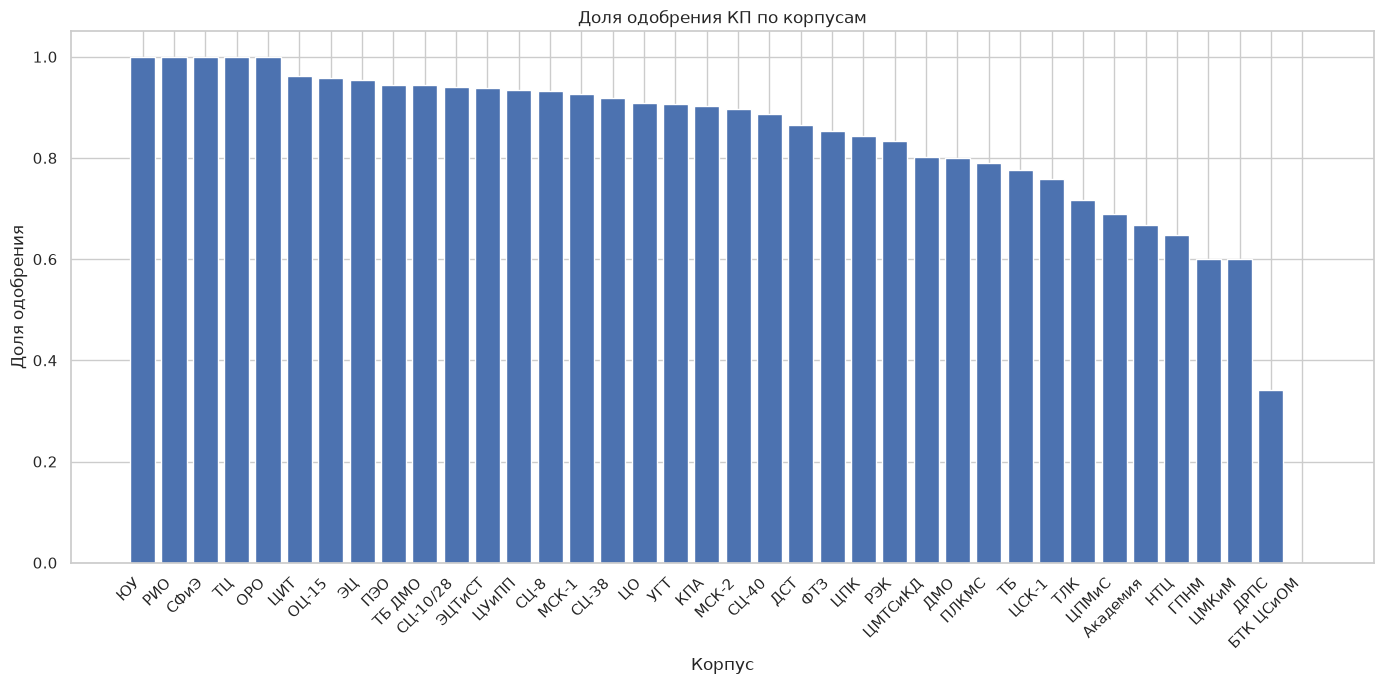

In [7]:
# ---------- Доля одобрения по корпусам ----------
approval_by_corpus = (
    df.groupby("Корпус")["is_approved"]
    .mean().sort_values(ascending=False)
)
plt.figure(figsize=(14, 7))
plt.bar(approval_by_corpus.index.astype(str),
        approval_by_corpus.values)
plt.title("Доля одобрения КП по корпусам")
plt.xlabel("Корпус")
plt.ylabel("Доля одобрения")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"figures/fig_04.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по корпусам

Есть большой разброс между корпусами, от 95,7% (ОЦ-15, n=467) и 95,4% (ЭЦ) до 60,1% (ЦМКиМ и ГПНМ); НТЦ — 64,8% при n=1 007, ЦПМиС — 68,9% при n=978. Хи-квадрат (H1) даёт p < 0,001, т.е. корпус статистически значимо связан с одобрением. При этом разрыв 35 п.п., скорее всего, показыает разницу в практике рассмотрения, а не в «качестве идей».

Крупные подразделения (НТЦ, ЦПМиС, ПЛКМС) одновременно дают много КП и имеют пониженную долю одобрения — именно там теряется основной поток идей.

Низкая доля одобрения может означать и строгий фильтр, и слабую проработку заявок на местах — по этим данным различить нельзя, нужен разбор причин отказов.

Корпус — один из самых сильных факторов; НТЦ, ЦПМиС, ГПНМ, ЦМКиМ — приоритет для разбора причин отказов.

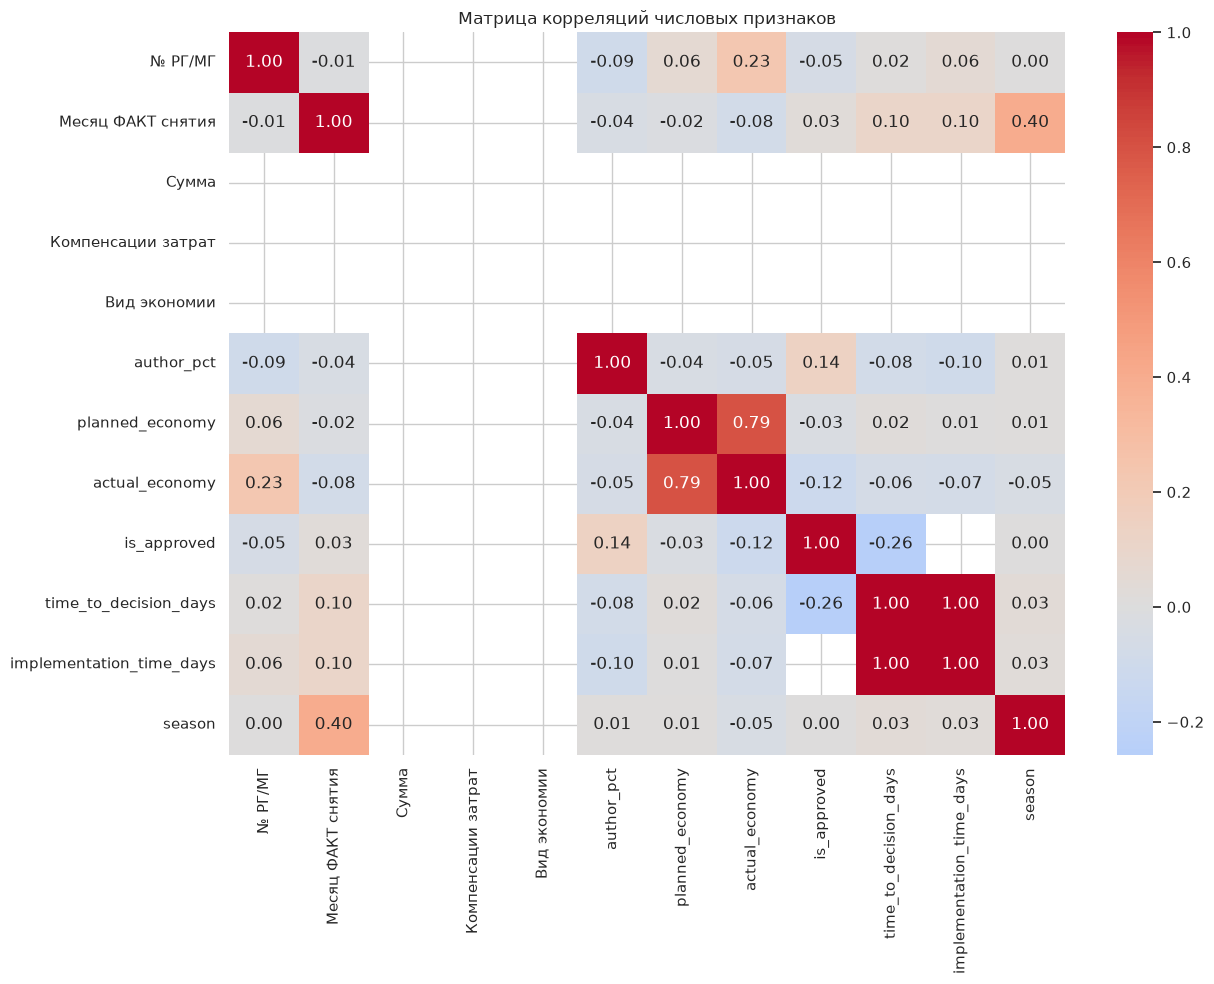

In [8]:
# ---------- Матрица корреляций ----------
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr(method="pearson")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций числовых признаков")
plt.tight_layout()
plt.savefig(f"figures/fig_05.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по корреляционной матрице

Сильные связи есть только между производными от дат признаками: `is_approved ↔ is_implemented / is_in_progress`, `time_to_decision_days ↔ implementation_time_days`, но это механические зависимости, а не закономерности процесса. Прямое следствие - эти поля нельзя подавать в модель как признаки: они содержат информацию из будущего (утечка целевой переменной).

Содержательные связи слабые: заявленная экономия практически не связана со сроком реализации (ρ = −0,006, H6), т.е. «дорогие» КП не реализуются дольше.

Многочисленные `NaN` в «Фактическом ЭЭ» и «Сроке выполнения» делают парные корреляции по ним нерепрезентативными.

Корреляции подтверждают, что процесс определяется организационными факторами (корпус, автор, статус), а не размером экономии; признаки-«последствия» нужно исключать из моделей.


АНАЛИЗ ВЫБРОСОВ
planned_economy: выбросов IQR = 970 (нормальный диапазон -411093.5 … 725737.7)
actual_economy: выбросов IQR = 44 (нормальный диапазон -311989.9 … 569467.7)
implementation_time_days: выбросов IQR = 1291 (нормальный диапазон -27.5 … 48.5)
time_to_decision_days: выбросов IQR = 2294 (нормальный диапазон -32.0 … 56.0)


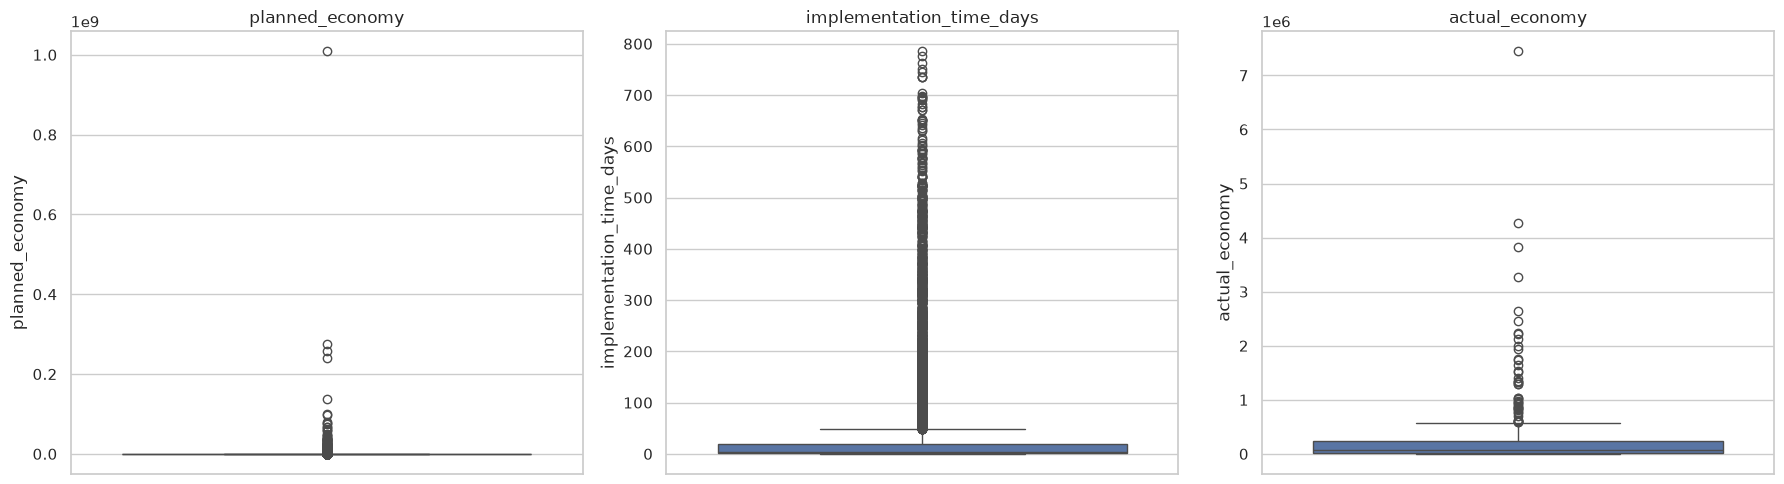

In [9]:
# ============================================================
# АНАЛИЗ ВЫБРОСОВ
# ============================================================
print("\n" + "=" * 60)
print("АНАЛИЗ ВЫБРОСОВ")
print("=" * 60)


def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum()), lower, upper


for col in ["planned_economy", "actual_economy",
            "implementation_time_days", "time_to_decision_days"]:
    if col in df.columns:
        series = df[col].dropna()
        n, lo, hi = iqr_outliers(series)
        print(f"{col}: выбросов IQR = {n} "
              f"(нормальный диапазон {lo:.1f} … {hi:.1f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(y=df["planned_economy"].dropna(), ax=axes[0])
axes[0].set_title("planned_economy")
sns.boxplot(y=df["implementation_time_days"].dropna(), ax=axes[1])
axes[1].set_title("implementation_time_days")
sns.boxplot(y=df["actual_economy"].dropna(), ax=axes[2])
axes[2].set_title("actual_economy")
plt.tight_layout()
plt.savefig(f"figures/fig_06.png", dpi=150, bbox_inches="tight")
plt.show()

### Выводы по выбросам

Выбросы массивны и закономерны, а не единичны. 970 по заявленной экономии (≈14% заполненных), 1 291 по сроку реализации (≈17%), 2 294 по времени до решения.

Границы IQR уходят в отрицательные значения (−411 тыс. по экономии, −27,5 дня по срокам), что является признаком сильно скошенных распределений с длинным правым хвостом. Однако, удалять такие наблюдения нельзя: это реальные крупные проекты и долгие согласования, они несут основную бизнес-информацию. Корректнее — логарифмирование, винзоризация или модели, устойчивые к выбросам (деревья).

Для интерпретации средних значений (например, «средняя экономия одобренных») выбросы критичны: они и создают разницу между медианой 28 тыс. и средним 748 тыс.

Распределения нужно логарифмировать, а в выводах опираться на медианы; удаление выбросов исказит картину.


АНАЛИЗ АВТОРОВ


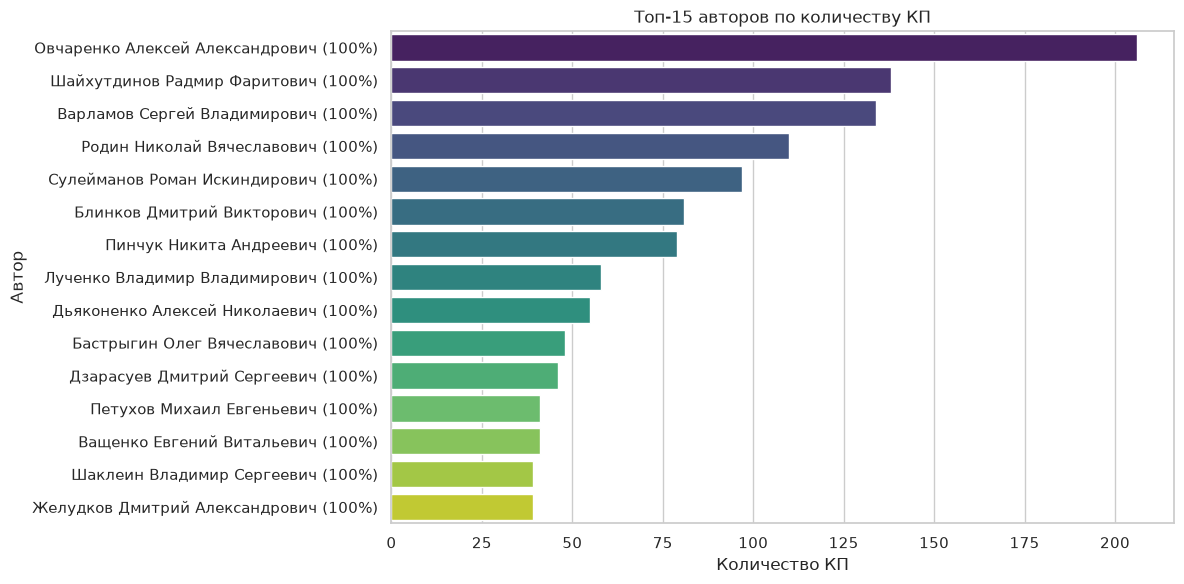


Статистика по авторам (≥5 КП):


,count,approval_rate,avg_pct,avg_planned
Автор,,,,
Абалдова Татьяна Викторовна (100%),5,1.0,100.0,17530.000000
Матвейчук Максим Васильевич (100%),7,1.0,100.0,10873.000000
Мироненко Артём Сергеевич (100%),28,1.0,100.0,202480.923750
Мирзоназаров Сарварджон Алиназарович (100%),25,1.0,100.0,NaN
Мелейчук Виталий Александрович (100%),5,1.0,100.0,NaN
"Машков Андрей Викторович (50%),Павлов Константин Романович (25%),Наджафов Вагиф Элшадович (25%)",12,1.0,50.0,NaN
"Машков Андрей Викторович (25%),Павлов Константин Романович (50%),Наджафов Вагиф Элшадович (25%)",6,1.0,25.0,NaN
Махмудов Камиль Рамазанович (100%),13,1.0,100.0,41081.666667
Матвейчук Валерия Витальевна (100%),21,1.0,100.0,10964.876667


In [10]:
# ============================================================
# АНАЛИЗ АВТОРОВ
# ============================================================
print("\n" + "=" * 60)
print("АНАЛИЗ АВТОРОВ")
print("=" * 60)

# Топ авторов по количеству КП
top_authors = df["Автор"].fillna("unknown").value_counts().head(15)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_authors.values, y=top_authors.index,
            palette="viridis")
plt.title("Топ-15 авторов по количеству КП")
plt.xlabel("Количество КП")
plt.tight_layout()
plt.savefig(f"figures/fig_07.png", dpi=150, bbox_inches="tight")
plt.show()

# Статистика по авторам (только те, у кого >= 5 КП)
author_stats = (
    df.groupby("Автор")
    .agg(
        count=("is_approved", "size"),
        approval_rate=("is_approved", "mean"),
        avg_pct=("author_pct", "mean"),
        avg_planned=("planned_economy", "mean"),
    )
    .query("count >= 5")
    .sort_values("approval_rate", ascending=False)
)
print("\nСтатистика по авторам (≥5 КП):")
display(author_stats.head(20))

### Выводы по авторам

В колонке «Автор» 6 632 различных значения, хотя реальных сотрудников заметно меньше: ФИО записаны вместе с процентом («Иванов И.И. (100%)») и через запятую для соавторов. Группировка по такой строке дробит статистику, её потребуется нормализовать при использовании.

Лидеры по числу КП: Овчаренко А.А. — 206, Шайхутдинов Р.Ф. — 138, Варламов С.В. — 134, Родин Н.В. — 110.

У большинства авторов с ≥5 КП `approval_rate = 1.0`: таблица отсортирована по доле одобрения, но такие значения чаще означают малую выборку, а не идеальное качество идей.

Средняя заявленная экономия у авторов различается на порядки (от ~10 тыс. до ~600 тыс.) — при сравнении авторов нужна нормализация и минимум 10–15 КП на человека.

Итог: автор - потенциально сильный признак, но только после нормализации ФИО и отсечения авторов с малым числом заявок.

In [11]:
# ============================================================
# СТАТИСТИЧЕСКИЕ ГИПОТЕЗЫ
# ============================================================

print("\n" + "=" * 60)
print("СТАТИСТИЧЕСКИЕ ГИПОТЕЗЫ")
print("=" * 60)

# ---------- H1. Одобрение зависит от корпуса ----------
contingency_table = pd.crosstab(df["Корпус"], df["is_approved"])
if contingency_table.shape[0] >= 2 and contingency_table.shape[1] >= 2:
    chi2, p_chi, dof_chi, expected = stats.chi2_contingency(contingency_table)
    print("\nH1: Хи-квадрат — одобрение и корпус")
    print(f"Chi2 = {chi2:.3f}, df = {dof_chi}, p = {p_chi:.5f}")
    print("Результат:",
          "статистически значимо" if p_chi < 0.05
          else "статистически незначимо")
else:
    print("\nH1: Недостаточно категорий для хи-квадрат.")

# ---------- H2. Экономия отличается между статусами ----------
approved_economy = df.loc[df["is_approved"] == 1, "planned_economy"].dropna()
not_approved_economy = df.loc[df["is_approved"] == 0, "planned_economy"].dropna()
if len(approved_economy) >= 2 and len(not_approved_economy) >= 2:
    t_stat, p_t = stats.ttest_ind(
        approved_economy, not_approved_economy,
        equal_var=False, alternative="two-sided",
    )
    print("\nH2: t-тест — плановая экономия")
    print(f"Средняя одобренных: {approved_economy.mean():.3f}")
    print(f"Средняя неодобренных: {not_approved_economy.mean():.3f}")
    print(f"t = {t_stat:.3f}, p = {p_t:.5f}")
else:
    print("\nH2: Недостаточно данных для t-теста.")

# ---------- H3. Время до решения ----------
approved_time = df.loc[df["is_approved"] == 1, "time_to_decision_days"].dropna()
not_approved_time = df.loc[df["is_approved"] == 0, "time_to_decision_days"].dropna()
if len(approved_time) > 0 and len(not_approved_time) > 0:
    u_stat, p_mw = stats.mannwhitneyu(
        approved_time, not_approved_time, alternative="two-sided"
    )
    print("\nH3: Манн — Уитни — время до решения")
    print(f"Медиана одобренных: {approved_time.median():.2f} дней")
    print(f"Медиана неодобренных: {not_approved_time.median():.2f} дней")
    print(f"U = {u_stat:.3f}, p = {p_mw:.5f}")
else:
    print("\nH3: Недостаточно данных для Манна — Уитни.")


СТАТИСТИЧЕСКИЕ ГИПОТЕЗЫ

H1: Хи-квадрат — одобрение и корпус
Chi2 = 1099.274, df = 37, p = 0.00000
Результат: статистически значимо

H2: t-тест — плановая экономия
Средняя одобренных: 748443.803
Средняя неодобренных: 1658947.452
t = -2.741, p = 0.00615

H3: Манн — Уитни — время до решения
Медиана одобренных: 2.00 дней
Медиана неодобренных: 35.00 дней
U = 5279917.000, p = 0.00000


### Выводы по гипотезам H1–H3

H1 подтверждена (p < 0,001): корпус значимо связан с одобрением — разрыв между подразделениями достигает 35 п.п.

H2 подтверждена, но с обратным знаком ожидания. У отклонённых КП заявленная экономия выше (среднее 1,66 млн против 748 тыс., p = 0,006). Причина в выбросах: медианы — 100 тыс. против 28 тыс., т.е. крупные заявки отклоняют чаще.

H3 подтверждена и наиболее практически полезна. Медиана времени до решения — 2 дня у одобренных против 35 дней у отклонённых (p < 0,001). КП, «висящее» в рассмотрении больше месяца, можно считать отклонённым и возвращать автору на доработку, не дожидаясь формального отказа.

Итог: корпус, размер заявленной экономии и длительность рассмотрения — значимые факторы; самый действенный рычаг — скорость принятия решения.

In [12]:
# ============================================================
# ДОПОЛНИТЕЛЬНЫЕ ГИПОТЕЗЫ H4–H6
# ============================================================

# ---------- H4. Одобрение зависит от task_status ----------
print("\nH4: Хи-квадрат — одобрение и task_status")
ct_task = pd.crosstab(df["task_status"], df["is_approved"])
if ct_task.shape[0] >= 2 and ct_task.shape[1] >= 2:
    chi2_4, p_4, dof_4, _ = stats.chi2_contingency(ct_task)
    print(f"Chi2 = {chi2_4:.3f}, df = {dof_4}, p = {p_4:.5f}")
    print("Результат:",
          "значимо" if p_4 < 0.05 else "незначимо")
else:
    print("Недостаточно категорий.")

# ---------- H5. author_pct отличается между статусами ----------
approved_pct = df.loc[df["is_approved"] == 1, "author_pct"].dropna()
rejected_pct = df.loc[df["is_approved"] == 0, "author_pct"].dropna()
if len(approved_pct) > 0 and len(rejected_pct) > 0:
    u5, p5 = stats.mannwhitneyu(approved_pct, rejected_pct,
                                alternative="two-sided")
    print("\nH5: Манн — Уитни — author_pct")
    print(f"Медиана одобренных: {approved_pct.median():.2f}%")
    print(f"Медиана неодобренных: {rejected_pct.median():.2f}%")
    print(f"U = {u5:.3f}, p = {p5:.5f}")
    print("Результат:",
          "значимо" if p5 < 0.05 else "незначимо")
else:
    print("\nH5: недостаточно данных.")

# ---------- H6. Корреляция planned_economy vs implementation_time_days ----------
sub_h6 = df[["planned_economy", "implementation_time_days"]].dropna()
if len(sub_h6) >= 5:
    rho, p6 = stats.spearmanr(sub_h6["planned_economy"],
                              sub_h6["implementation_time_days"])
    print("\nH6: Spearman — planned_economy vs implementation_time_days")
    print(f"rho = {rho:.3f}, p = {p6:.5f}")
    print("Результат:",
          "значимая связь" if p6 < 0.05 else "связи не обнаружено")
else:
    print("\nH6: недостаточно данных.")


H4: Хи-квадрат — одобрение и task_status
Chi2 = 546.355, df = 4, p = 0.00000
Результат: значимо

H5: Манн — Уитни — author_pct
Медиана одобренных: 100.00%
Медиана неодобренных: 50.00%
U = 16228798.000, p = 0.00000
Результат: значимо

H6: Spearman — planned_economy vs implementation_time_days
rho = -0.006, p = 0.76041
Результат: связи не обнаружено


### Выводы по гипотезам H4–H6

H4 формально подтверждена (p < 0,001), но интерпретировать её нужно осторожно: `task_status` содержит значения «реализ / рассм / внедр», т.е. описывает текущее состояние КП и частично совпадает с целевой переменной.

H5 подтверждена. У одобренных медиана доли автора — 100%, у отклонённых — 50% (p < 0,001). КП, поданные коллективом из 2+ человек, отклоняются значимо чаще — вероятно, из-за размытой ответственности и более сложных заявок.

H6 не подтверждена, связь между заявленной экономией и сроком реализации отсутствует (ρ = −0,006, p = 0,76). «Дорогие» КП не реализуются дольше — значит, сложность проекта определяется не суммой.

Итог: единственный новый содержательный инсайт — эффект коллективного авторства; `task_status` нужно исключить из признаков или заменить на нейтральный.